# Transforms

You will build: a flower badge made from one petal turned, mirrored and moved into place.

Run it from this folder with ``python transforms.py``, or open ``transforms.ipynb``.

In [1]:
import svgwriter as svg

Start with a dark rounded tile.

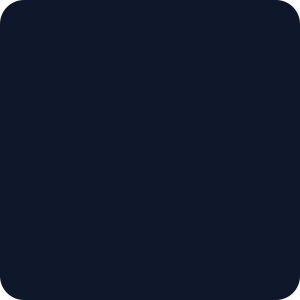

In [2]:
SIZE = 300
CENTER = (SIZE / 2, SIZE / 2)
PETALS = 12

doc = svg.Document(SIZE, SIZE)
doc.rect(0, 0, SIZE, SIZE, rx=24, fill="#0f172a")
doc

Draw one petal above the centre.

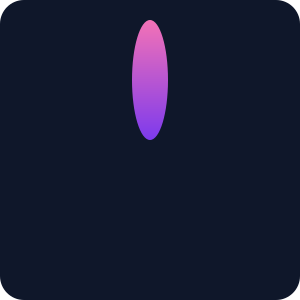

In [3]:
petal = svg.ellipse(SIZE / 2, SIZE / 2 - 70, 18, 60, fill=svg.LinearGradient.vertical("#f472b6", "#7c3aed"))
doc.add(petal.clone())
doc

`rotate(angle, about=point)` turns a shape around a point. Twelve turned copies make a ring.

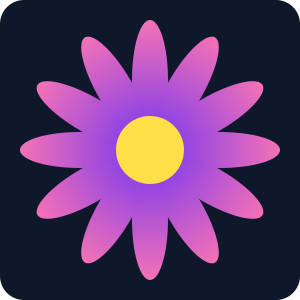

In [4]:
for i in range(1, PETALS):
    doc.add(petal.clone()).rotate(360 * i / PETALS, about=CENTER)
doc.circle(*CENTER, 34, fill="#fde047")
doc

`flip_x` and `flip_y` mirror a copy: one corner arrow becomes four.

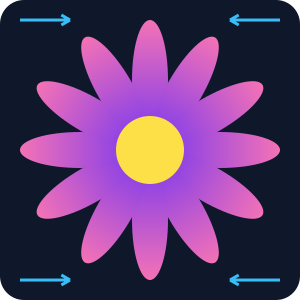

In [5]:
corner = svg.paths.arrow(20, 20, 70, 20, head=10, stroke="#38bdf8", stroke_width=3)
doc += [
    corner,
    corner.clone().flip_x(about=CENTER),
    corner.clone().flip_y(about=CENTER),
    corner.clone().flip_x(about=CENTER).flip_y(about=CENTER),
]
doc

`place(x, y)` moves a shape drawn around (0, 0) to a spot: here a name tag at the bottom.

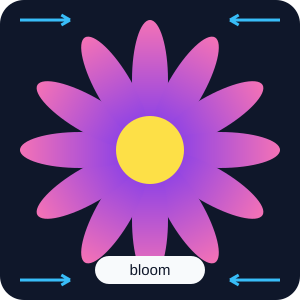

In [6]:
tag = svg.rect.from_center((0, 0), (110, 28), rx=14, fill="#f8fafc")
doc += tag.place(SIZE / 2, SIZE - 30)
doc.text("bloom", x=SIZE / 2, y=SIZE - 25, font_size=15, text_anchor="middle", fill="#0f172a",
         font_family="Arial, Helvetica, sans-serif")
doc

Save an SVG and a PNG at twice the size. Next: [03 Alignment](../03_alignment/alignment.py).

In [7]:
doc.save("02_transforms.svg")
doc.save("02_transforms.png", scale=2)